# Ek 7: Anahtar Kesit Duyarliligi, Registration Alt Siniri ve Yari-Toraks Ayrimi

Yeniden egitim yoktur. Yayilim islevleri ana not defteriyle aynidir. T4 veya L4 uzerinde yaklasik 20-30 dakika surer.

1. **Anahtar kesit secimi:** ana analizde uzman etiketi referans alani en buyuk kesite verildi (iyimser). Burada ayrica
   **orta kesit** (hastanin kesit dizisinin ortasina en yakin pozitif kesit) ve **rastgele pozitif kesit** (tohum 42) denenir.
2. **Registration tabanli alt sinir (B3):** anahtar kesitteki uzman maskesi, yogun optik akisla (OpenCV DIS) her kesite
   egilip bukulerek tasinir. Maske kopyalamadan (B2) daha guclu, egitimsiz bir karsilastirmadir.
3. **Yari-toraks ayrimi:** goruntu orta hatti ile govde maskesinin agirlik merkezi karsilastirilir.
4. **Sekil 3 (yeni):** ayni ornek hasta, yakinlastirilmis kirpimlarla ve serif yaziyla.

Calistirma: GPU secin ve **Tumunu calistir** deyin. Ciktilar Drive'da `pnx_ek_analizler` klasorune yazilir:
`TABLO_ek7_anahtar.csv`, `TABLO_ek7_kayit.csv`, `TABLO_ek7_yaritoraks.csv`, `Figure3_example_patient.png/.pdf`.

In [1]:
!pip install -q segmentation_models_pytorch==0.5.0 opencv-python-headless pillow scipy matplotlib pandas scikit-learn
!rm -rf /content/sam2
!git clone -q https://github.com/facebookresearch/sam2.git /content/sam2
%cd /content/sam2
!SAM2_BUILD_CUDA=0 pip install -q -e .
!mkdir -p checkpoints
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_small.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_base_plus.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt
%cd /content
!apt-get -qq install -y fonts-liberation > /dev/null

/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
/content


### Ortak yardimci modul
Asagidaki hucre `pnx_ortak.py` dosyasini Colab diskine yazar. Degistirmeniz gerekmez.

In [2]:
%%writefile /content/pnx_ortak.py
# -*- coding: utf-8 -*-
"""
pnx_ortak.py - Pnomotoraks BT analizi icin ortak yardimci modul.

Veri hazirlama, hasta bazli bolme, U-Net cikarimi (kayan pencere ve tam cozunurluk), SAM2 goruntu ve
video modu, birlestirme kurali, guvenilirlik katsayisi ve metrik fonksiyonlarini icerir.
Sabit tohumla (SEED=42) hasta bazli egitim/dogrulama/test bolmesi uretilir.

Colab'da kullanim:
    import sys; sys.path.insert(0, '/content')
    import pnx_ortak as po
    po.init_unet(); po.init_sam2_image()
"""
import os, glob, random, time
import numpy as np
import cv2
import torch
from PIL import Image
from scipy import ndimage

# ---------------------------------------------------------------------------
# Yapilandirma
# ---------------------------------------------------------------------------
RAW_DIR = '/content/drive/MyDrive/CT_goruntuler_anon'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/pnx_artifacts'
UNET_WEIGHT_PATH = f'{DRIVE_BACKUP_DIR}/pnomotoraks_unet.pth'

SAM2_REPO_DIR = '/content/sam2'
SAM2_CHECKPOINT = '/content/sam2/checkpoints/sam2.1_hiera_small.pt'
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_s.yaml'

IMAGE_SIZE = 224
PATCH_STRIDE = 224
SEED = 42
PNEUMOTHORAX_LABEL = 1
LUNG_LABEL = 2
TRAIN_RATIO = 0.65
VAL_RATIO = 0.10

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

unet_model = None
sam2_image_predictor = None
_sam2_base_model = None

# Segmentasyon modeli ve son isleme ayarlari. Varsayilan: 224x224 parca U-Net, esik 0.5, 80 pikselden kucuk
# bilesenleri at, yalnizca en buyuk bileseni tut. Dogrulamada secilen ayarlar load_segmenter_config() ile yuklenir.
SEG = {
    'kind': 'unet_patch',     # 'unet_patch' (parca U-Net) | 'guclu' (tam cozunurluklu ResNet34 U-Net)
    'threshold': 0.5,
    'min_area': 80,
    'keep': 'largest',        # 'largest' | 'all' | 'top2'
    'tta': False,             # yatay cevirme ile test-zamani artirma
    'lung_filter': False,     # yalnizca 'guclu': akciger olasiligi yuksek bolgeye dusen pnomotoraks bilesenlerini at
}
strong_model = None
LAST_LUNG_PROB = None


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Veri: hasta indeksi ve hasta bazli bolme
# ---------------------------------------------------------------------------
def _slice_sort_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return (0, int(stem)) if stem.isdigit() else (1, stem)


def find_pairs_for_patient(patient_dir, numeric_order=False):
    # numeric_order=False: alfabetik siralama.
    # numeric_order=True : kesitleri sayisal sirada dondurur (video/sekans isleme icin;
    #                      '10.jpg' '2.jpg'den once gelmesin).
    pairs = []
    jpg_files = sorted(glob.glob(os.path.join(patient_dir, '*.jpg')))
    if numeric_order:
        jpg_files = sorted(jpg_files, key=_slice_sort_key)
    for jpg_path in jpg_files:
        stem = os.path.splitext(os.path.basename(jpg_path))[0]
        png_path = os.path.join(patient_dir, stem + '.png')
        if os.path.exists(png_path):
            pairs.append((jpg_path, png_path))
    return pairs


def build_patient_split(raw_dir=RAW_DIR, seed=SEED, numeric_order=True):
    """Sabit tohumla hasta bazli bolme uretir.

    Donus: patient_index {pid: [(jpg, png), ...]}, split_of_patient {pid: 'train'|'val'|'test'}
    """
    patient_dirs = sorted([d for d in glob.glob(os.path.join(raw_dir, '*')) if os.path.isdir(d)])
    patient_index = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir)
        pairs = find_pairs_for_patient(pdir, numeric_order=numeric_order)
        if len(pairs) > 0:
            patient_index[pid] = pairs

    # Uyari: yalnizca kucuk harfli .jpg/.png ciftleri kullanilir. .jpeg veya .PNG gibi uzantilar Linux/Colab'da
    # eslesmez ve atlanir. Atlanan dosyalar burada listelenir.
    atlanan = [os.path.relpath(f, raw_dir) for d in patient_dirs for f in glob.glob(os.path.join(d, '*'))
               if not f.endswith(('.jpg', '.png'))]
    if atlanan:
        print(f'UYARI: standart disi uzantili {len(atlanan)} dosya kullanilmadi (ornek: {atlanan[:3]})')

    patient_ids = sorted(patient_index.keys())
    rng = random.Random(seed)
    rng.shuffle(patient_ids)
    n = len(patient_ids)
    n_train = int(round(n * TRAIN_RATIO))
    n_val = int(round(n * VAL_RATIO))
    split_of_patient = {}
    for pid in patient_ids[:n_train]:
        split_of_patient[pid] = 'train'
    for pid in patient_ids[n_train:n_train + n_val]:
        split_of_patient[pid] = 'val'
    for pid in patient_ids[n_train + n_val:]:
        split_of_patient[pid] = 'test'
    return patient_index, split_of_patient


def load_image_rgb(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_label_map(mask_path):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return m


def load_binary_mask(mask_path, label=PNEUMOTHORAX_LABEL):
    return (load_label_map(mask_path) == label).astype(np.uint8)


# ---------------------------------------------------------------------------
# Morfolojik yardimcilar ve rapor yardimcilari
# ---------------------------------------------------------------------------
def clean_mask(mask, min_area=80):
    mask = (mask > 0).astype(np.uint8)
    labeled, num = ndimage.label(mask)
    out = np.zeros_like(mask, dtype=np.uint8)
    for i in range(1, num + 1):
        region = (labeled == i)
        if region.sum() >= min_area:
            out[region] = 1
    return out


def largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask.astype(np.uint8)
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(np.uint8)


def keep_components(mask, keep=None):
    keep = SEG['keep'] if keep is None else keep
    mask = (mask > 0).astype(np.uint8)
    if keep == 'largest':
        return largest_component(mask)
    if keep == 'top2':
        labeled, num = ndimage.label(mask)
        if num <= 2:
            return mask
        sizes = ndimage.sum(mask, labeled, range(1, num + 1))
        top = np.argsort(sizes)[::-1][:2] + 1
        return np.isin(labeled, top).astype(np.uint8)
    return mask


def postprocess_mask(mask, min_area=None, keep=None):
    """Ikili maskeye SEG ayarlarina gore kucuk bilesen temizligi + bilesen politikasi uygular."""
    return keep_components(clean_mask(mask, SEG['min_area'] if min_area is None else min_area), keep)


def area_ratio(mask):
    return float(mask.sum() / mask.size)


def estimate_side(mask, radiological_convention=True):
    """Pnomotoraksin tarafini tahmin eder.

    DIKKAT: Aksiyel BT goruntuleri radyolojik konvansiyonda gosterilir; goruntunun
    SOL yarisi hastanin SAG tarafidir. Varsayilan olarak radyolojik konvansiyon kullanilir.
    Goruntu cercevesine gore taraf gerekiyorsa radiological_convention=False verin.
    """
    if mask.sum() == 0:
        return 'belirgin degil'
    h, w = mask.shape
    img_left = mask[:, :w // 2].sum()
    img_right = mask[:, w // 2:].sum()
    if radiological_convention:
        side_of_img_left, side_of_img_right = 'sag', 'sol'
    else:
        side_of_img_left, side_of_img_right = 'sol', 'sag'
    if img_left > img_right * 1.2:
        return side_of_img_left
    elif img_right > img_left * 1.2:
        return side_of_img_right
    return 'bilateral'


def estimate_extent(mask):
    r = area_ratio(mask)
    if r < 0.005:
        return 'cok kucuk'
    elif r < 0.02:
        return 'kucuk'
    elif r < 0.06:
        return 'orta'
    return 'genis'


def make_overlay(image_np, mask, color=(255, 0, 0), alpha=0.35):
    overlay = image_np.copy()
    m = mask.astype(bool)
    col = np.array(color, dtype=np.float32)
    overlay[m] = ((1 - alpha) * overlay[m] + alpha * col).astype(np.uint8)
    return overlay


def mask_iou(mask_a, mask_b):
    inter = np.logical_and(mask_a > 0, mask_b > 0).sum()
    union = np.logical_or(mask_a > 0, mask_b > 0).sum()
    return 0.0 if union == 0 else float(inter) / float(union)


def mask_box(mask, margin=10):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)
    return np.array([max(0, xs.min() - margin), max(0, ys.min() - margin),
                     min(w - 1, xs.max() + margin), min(h - 1, ys.max() + margin)])


# ---------------------------------------------------------------------------
# Metrikler
# ---------------------------------------------------------------------------
def segmentation_metrics(pred_mask, gt_mask, eps=1e-6):
    p = pred_mask.flatten().astype(np.uint8)
    g = gt_mask.flatten().astype(np.uint8)
    tp = int(np.sum((p == 1) & (g == 1)))
    tn = int(np.sum((p == 0) & (g == 0)))
    fp = int(np.sum((p == 1) & (g == 0)))
    fn = int(np.sum((p == 0) & (g == 1)))
    sens = (tp + eps) / (tp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    return {
        'dice': (2 * tp + eps) / (2 * tp + fp + fn + eps),
        'iou': (tp + eps) / (tp + fp + fn + eps),
        'accuracy': (tp + tn + eps) / (tp + tn + fp + fn + eps),
        'sensitivity': sens,
        'specificity': (tn + eps) / (tn + fp + eps),
        'precision': prec,
        'f1': (2 * prec * sens + eps) / (prec + sens + eps),
    }


def hd95_pixels(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask = (gt_mask > 0).astype(np.uint8)
    if pred_mask.sum() == 0 or gt_mask.sum() == 0:
        return float('nan')
    pb = pred_mask - ndimage.binary_erosion(pred_mask).astype(np.uint8)
    gb = gt_mask - ndimage.binary_erosion(gt_mask).astype(np.uint8)
    if pb.sum() == 0 or gb.sum() == 0:
        return float('nan')
    gt_dt = ndimage.distance_transform_edt(1 - gb)
    pr_dt = ndimage.distance_transform_edt(1 - pb)
    return float(max(np.percentile(gt_dt[pb > 0], 95), np.percentile(pr_dt[gb > 0], 95)))


def hemithorax_counts(pred_mask, gt_mask, min_pixels=50):
    """Yari-toraks (goruntunun sol/sag yarisi) duzeyinde tespit sayimlari.

    Veri setindeki kesitlerin neredeyse tamami pnomotoraks pozitiftir (851/852), bu yuzden kesit
    duzeyinde ozgulluk olculemez. Pnomotoraks cogunlukla tek tarafli oldugundan, referans maskede pnomotoraks
    olmayan karsi yari-toraks dogal bir negatif ornektir; burada tahmin edilen maske varsa yanlis pozitiftir.
    Donus: {'tp','fn','tn','fp'} (iki yari uzerinden toplam)."""
    w = gt_mask.shape[1]
    c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, w // 2), slice(w // 2, w)):
        g = gt_mask[:, sl].sum() >= min_pixels
        p = pred_mask[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


def dice_3d(pred_vol, gt_vol, eps=1e-6):
    p = pred_vol > 0
    g = gt_vol > 0
    inter = np.logical_and(p, g).sum()
    return float((2 * inter + eps) / (p.sum() + g.sum() + eps))


def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=SEED):
    values = np.asarray([v for v in values if not np.isnan(v)])
    if len(values) == 0:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return float(values.mean()), float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


# ---------------------------------------------------------------------------
# U-Net
# ---------------------------------------------------------------------------
def init_unet(weight_path=UNET_WEIGHT_PATH):
    global unet_model
    import segmentation_models_pytorch as smp
    unet_model = smp.Unet(encoder_name='mobilenet_v2', encoder_weights=None,
                          in_channels=3, classes=1, activation=None).to(DEVICE)
    unet_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    unet_model.eval()
    print('U-Net yuklendi:', weight_path)
    return unet_model


_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def _to_tensor(patch_rgb):
    x = (patch_rgb.astype(np.float32) / 255.0 - _MEAN) / _STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)


def unet_prob_map(image_np, tta=None):
    """Aktif segmentasyon modeliyle tam goruntu pnomotoraks olasilik haritasi (HxW, 0-1).
    SEG['kind'] == 'guclu' ise tam cozunurluk modeli, aksi halde 224x224 parca U-Net kullanilir."""
    global LAST_LUNG_PROB
    tta = SEG['tta'] if tta is None else tta
    fn = _strong_prob if SEG['kind'] == 'guclu' else _patch_unet_prob_map
    p, lung = fn(image_np)
    if tta:
        p2, lung2 = fn(np.ascontiguousarray(image_np[:, ::-1]))
        p = (p + p2[:, ::-1]) / 2
        if lung is not None:
            lung = (lung + lung2[:, ::-1]) / 2
    LAST_LUNG_PROB = lung
    return p


@torch.no_grad()
def _strong_prob(image_np):
    h, w = image_np.shape[:2]
    H, W = int(np.ceil(h / 32) * 32), int(np.ceil(w / 32) * 32)
    img = cv2.copyMakeBorder(image_np, 0, H - h, 0, W - w, cv2.BORDER_CONSTANT, value=0)
    x = _to_tensor(img).to(DEVICE)
    with torch.autocast('cuda', enabled=(DEVICE == 'cuda')):
        out = torch.sigmoid(strong_model(x).float())[0].cpu().numpy()
    lung = out[1, :h, :w] if out.shape[0] > 1 else None
    return out[0, :h, :w], lung


def init_strong_model(weight_path, arch='Unet', encoder='resnet34', classes=2):
    global strong_model
    import segmentation_models_pytorch as smp
    strong_model = getattr(smp, arch)(encoder_name=encoder, encoder_weights=None, in_channels=3, classes=classes).to(DEVICE)
    strong_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    strong_model.eval()
    SEG['kind'] = 'guclu'
    print('Guclu segmentasyon modeli yuklendi:', weight_path, arch, encoder)
    return strong_model


def load_segmenter_config(path):
    """Segmenter ayar dosyasini (model agirligi + dogrulamada secilen son isleme) yukler."""
    import json as _json
    cfg = _json.load(open(path))
    if cfg.get('kind') == 'guclu':
        init_strong_model(cfg['weight_path'], cfg.get('arch', 'Unet'), cfg.get('encoder', 'resnet34'), cfg.get('classes', 2))
    elif unet_model is None:
        init_unet()
    for k in ('kind', 'threshold', 'min_area', 'keep', 'tta', 'lung_filter'):
        if k in cfg:
            SEG[k] = cfg[k]
    print('Segmenter ayari:', SEG)
    return cfg


@torch.no_grad()
def _patch_unet_prob_map(image_np, patch_size=IMAGE_SIZE, stride=PATCH_STRIDE, batch_size=16):
    """Kaydirmali pencere ile tam goruntu olasilik haritasi (HxW, 0-1) (parca U-Net)."""
    h, w = image_np.shape[:2]
    ys = [0] if h <= patch_size else sorted(set(list(range(0, h - patch_size, stride)) + [h - patch_size]))
    xs = [0] if w <= patch_size else sorted(set(list(range(0, w - patch_size, stride)) + [w - patch_size]))
    prob_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    coords, tensors = [], []
    for y in ys:
        for x in xs:
            patch = image_np[y:y + patch_size, x:x + patch_size]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                patch = cv2.copyMakeBorder(patch, 0, patch_size - ph, 0, patch_size - pw, cv2.BORDER_CONSTANT, value=0)
            coords.append((y, x, ph, pw))
            tensors.append(_to_tensor(patch))
    for i in range(0, len(tensors), batch_size):
        batch = torch.cat(tensors[i:i + batch_size]).to(DEVICE)
        probs = torch.sigmoid(unet_model(batch))[:, 0].cpu().numpy()
        for (y, x, ph, pw), pr in zip(coords[i:i + batch_size], probs):
            prob_map[y:y + ph, x:x + pw] += pr[:ph, :pw]
            count_map[y:y + ph, x:x + pw] += 1.0
    count_map[count_map == 0] = 1.0
    return prob_map / count_map, None


def mask_from_prob(prob, lung_prob=None, threshold=None, min_area=None, keep=None, lung_filter=None):
    threshold = SEG['threshold'] if threshold is None else threshold
    lung_filter = SEG['lung_filter'] if lung_filter is None else lung_filter
    m = clean_mask((prob > threshold).astype(np.uint8), SEG['min_area'] if min_area is None else min_area)
    if lung_filter and lung_prob is not None and m.sum() > 0:
        # Pnomotoraks akciger parankiminin DISINDA (plevral bosluk) yer alir; akciger olasiligi
        # yuksek bolgeyle cogunlukla ortusen bilesenler yanlis pozitif kabul edilir.
        lab, n = ndimage.label(m)
        for j in range(1, n + 1):
            reg = lab == j
            if lung_prob[reg].mean() > 0.5:
                m[reg] = 0
    return keep_components(m, keep)


def unet_predict(image_np, threshold=None):
    """Cikti: (maske, guven, olasilik haritasi). Son isleme SEG ayarlarina gore yapilir."""
    prob = unet_prob_map(image_np)
    mask = mask_from_prob(prob, LAST_LUNG_PROB, threshold=threshold)
    return mask, float(prob.max()), prob


# ---------------------------------------------------------------------------
# SAM2 (goruntu modu)
# ---------------------------------------------------------------------------
def _sam2_import():
    import sys
    if SAM2_REPO_DIR not in sys.path:
        sys.path.insert(0, SAM2_REPO_DIR)


def init_sam2_image():
    global sam2_image_predictor, _sam2_base_model
    _sam2_import()
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    _sam2_base_model = build_sam2(config_file=SAM2_CONFIG, ckpt_path=SAM2_CHECKPOINT, device=DEVICE)
    sam2_image_predictor = SAM2ImagePredictor(_sam2_base_model)
    print('SAM2 (goruntu modu) hazir.')
    return sam2_image_predictor


def init_sam2_video(offload_video_to_cpu=False):
    _sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    vp = build_sam2_video_predictor(SAM2_CONFIG, SAM2_CHECKPOINT, device=DEVICE)
    print('SAM2 (video modu) hazir.')
    return vp


@torch.no_grad()
def sam2_set_image(image_np):
    sam2_image_predictor.set_image(image_np)


@torch.no_grad()
def sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10, multimask_select='score',
                 image_already_set=False):
    """SAM2 goruntu modu tahmini.

    prompt_type: 'box' | 'point' | 'box+point'
    multimask_select: 'score' (en yuksek SAM skoru) |
                      'agreement' (U-Net maskesiyle en yuksek IoU'lu aday)
    SEG['keep'] != 'largest' ise U-Net maskesinin her bagli bileseni (or. iki tarafli pnomotoraks)
    icin ayri istem verilir ve sonuclar birlestirilir.
    """
    if not image_already_set:
        sam2_image_predictor.set_image(image_np)
    if SEG['keep'] != 'largest' and unet_mask.sum() > 0:
        lab, n = ndimage.label(unet_mask > 0)
        if n > 1:
            out, skorlar, alanlar = np.zeros_like(unet_mask, dtype=np.uint8), [], []
            for j in range(1, n + 1):
                comp = (lab == j).astype(np.uint8)
                m, s = _sam2_tek(image_np, comp, prompt_type, box_margin, multimask_select)
                out = np.logical_or(out, m).astype(np.uint8)
                skorlar.append(s); alanlar.append(comp.sum())
            return keep_components(out), float(np.average(skorlar, weights=alanlar))
    return _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select)


def _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select):
    h, w = image_np.shape[:2]
    has_mask = unet_mask.sum() > 0
    box = mask_box(unet_mask, box_margin) if has_mask else np.array([int(w * .05), int(h * .05), int(w * .95), int(h * .95)])
    if has_mask:
        ys, xs = np.where(unet_mask > 0)
        # Agirlik merkezi maskenin disina dusebilir (hilal seklindeki pnomotoraks);
        # bu yuzden maske icinde merkeze en yakin piksel kullanilir.
        cy, cx = ys.mean(), xs.mean()
        j = int(np.argmin((ys - cy) ** 2 + (xs - cx) ** 2))
        point = np.array([[int(xs[j]), int(ys[j])]])
    else:
        point = np.array([[w // 2, h // 2]])

    kwargs = dict(multimask_output=True)
    if prompt_type == 'box':
        kwargs.update(point_coords=None, point_labels=None, box=box)
    elif prompt_type == 'point':
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=None)
    else:
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=box)
    masks, scores, _ = sam2_image_predictor.predict(**kwargs)

    # Tek bir bilesen/istem icin SAM2 cikti adayinin en buyuk bileseni alinir.
    cands = [largest_component(clean_mask(m.astype(np.uint8))) for m in masks]
    if multimask_select == 'agreement' and has_mask:
        best = int(np.argmax([mask_iou(c, unet_mask) for c in cands]))
    else:
        best = int(np.argmax(scores))
    return cands[best], float(scores[best])


def combine_masks(unet_mask, sam_mask, min_agreement_iou=0.3):
    # Kural: U-Net negatifse bos, uyum dusukse U-Net maskesine geri dus.
    # Bilesen politikasi SEG['keep'] ile belirlenir (varsayilan 'largest').
    if unet_mask.sum() == 0:
        return np.zeros_like(sam_mask, dtype=np.uint8)
    if mask_iou(unet_mask, sam_mask) < min_agreement_iou:
        return postprocess_mask(unet_mask)
    return postprocess_mask(np.logical_or(unet_mask > 0, sam_mask > 0).astype(np.uint8))


def compute_reliability(unet_conf, sam_conf, final_mask, wU=0.35, wS=0.45, wA=0.20):
    area_term = min(area_ratio(final_mask) / 0.03, 1.0)
    return float(max(0.0, min(1.0, wU * unet_conf + wS * sam_conf + wA * area_term)))


def baseline_pipeline(image_np):
    """Tek gecisli hat: U-Net -> SAM2 kutu istemi -> birlestirme."""
    t0 = time.time()
    unet_mask, unet_conf, prob = unet_predict(image_np)
    sam_mask, sam_conf = sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10)
    final = combine_masks(unet_mask, sam_mask)
    return {
        'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
        'unet_conf': unet_conf, 'sam_conf': sam_conf, 'prob': prob,
        'reliability': compute_reliability(unet_conf, sam_conf, final),
        'time_s': time.time() - t0,
    }


# ---------------------------------------------------------------------------
# Anatomik olabilirlik yardimcilari (dogrulama denetimleri icin)
# ---------------------------------------------------------------------------
def body_mask(image_np, thr=20):
    """Govde (vucut) maskesi: goruntu esiklenir, en buyuk bilesen alinir, delikleri doldurulur.
    Pnomotoraks havasi govde ICINDE, hasta disindaki hava govde DISINDA kalir."""
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    m = (gray > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    m = largest_component(m)
    return ndimage.binary_fill_holes(m).astype(np.uint8)


def mean_intensity_in_mask(image_np, mask):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    return float(gray[mask > 0].mean()) if mask.sum() > 0 else float('nan')


# ---------------------------------------------------------------------------
# VLM (Qwen2-VL)
# ---------------------------------------------------------------------------
vlm_model = None
vlm_processor = None
VLM_MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'


def init_vlm(model_id=VLM_MODEL_ID):
    global vlm_model, vlm_processor, VLM_MODEL_ID
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    VLM_MODEL_ID = model_id
    vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map='auto')
    vlm_processor = AutoProcessor.from_pretrained(model_id)
    print('VLM hazir:', model_id)


@torch.no_grad()
def vlm_generate(image_pil, prompt_text, max_new_tokens=400, temperature=0.6, seed=None):
    from qwen_vl_utils import process_vision_info
    if seed is not None:
        torch.manual_seed(seed)
    messages = [{'role': 'user', 'content': [{'type': 'image', 'image': image_pil}, {'type': 'text', 'text': prompt_text}]}]
    chat = vlm_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = vlm_processor(text=[chat], images=image_inputs, videos=video_inputs, padding=True, return_tensors='pt').to(DEVICE)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=temperature, top_p=0.9, repetition_penalty=1.3)
    trimmed = [o[len(i):] for i, o in zip(inputs.input_ids, out)]
    return vlm_processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

Writing /content/pnx_ortak.py


In [3]:
import os, sys, json, time, shutil, itertools
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import torch
from scipy import ndimage, stats

assert torch.cuda.is_available(), 'GPU yok: Calisma zamani turunu GPU yapip yeniden baslatin'
from google.colab import drive
drive.mount('/content/drive')
sys.path.insert(0, '/content')
import pnx_ortak as po

font_manager._load_fontmanager(try_read_cache=False)
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Liberation Serif', 'DejaVu Serif'], 'font.size': 10, 'pdf.fonttype': 42})
po.set_seed()
D = '/content/drive/MyDrive'


def bul(*yollar):
    # Ilk calistirmadaki ve yayin surumundeki Drive klasor adlarinin ikisi de denenir
    for y in yollar:
        if os.path.exists(y):
            print('Bulundu:', y)
            return y
    raise FileNotFoundError('Hicbiri bulunamadi, yolu elle girin: ' + ' | '.join(yollar))


GUCLU_YOL = bul(f'{D}/pnx_model/unet_resnet34_pnomotoraks.pth', f'{D}/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth',
                f'{D}/pnx_taban/guclu_Unet_resnet34_akcigersiz.pth')
GUCLU_SEG = dict(kind='guclu', threshold=0.3, min_area=20, keep='top2', tta=True, lung_filter=False)
SAM2_VIDEO_ADAYLAR = {
    'S': ('configs/sam2.1/sam2.1_hiera_s.yaml', '/content/sam2/checkpoints/sam2.1_hiera_small.pt'),
    'B+': ('configs/sam2.1/sam2.1_hiera_b+.yaml', '/content/sam2/checkpoints/sam2.1_hiera_base_plus.pt'),
}
ANA_BOYUT, TAU_Y = 'B+', 0.5      # ana analizde dogrulamada secilenler
OUT_DIR = f'{D}/pnx_ek_analizler'
FRAME_ROOT = '/content/pnx_frames'
os.makedirs(OUT_DIR, exist_ok=True)

patient_index, split_of_patient = po.build_patient_split(numeric_order=True)
test_patients = sorted([p for p, s in split_of_patient.items() if s == 'test'])
po.init_strong_model(GUCLU_YOL, 'Unet', 'resnet34', classes=1)
po.SEG.update(GUCLU_SEG)
po.init_sam2_image()


def video_tahminci(boyut):
    po._sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    cfg, ckpt = SAM2_VIDEO_ADAYLAR[boyut]
    return build_sam2_video_predictor(cfg, ckpt, device=po.DEVICE)


VIDEO = {b: video_tahminci(b) for b in SAM2_VIDEO_ADAYLAR}
print('test:', len(test_patients), 'hasta')

Mounted at /content/drive
Bulundu: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth
UYARI: standart disi uzantili 27 dosya kullanilmadi (ornek: ['1426520/4.PNG', '1637290/5.jpeg', '1757286/2.jpeg'])
Guclu segmentasyon modeli yuklendi: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth Unet resnet34


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


SAM2 (goruntu modu) hazir.
test: 43 hasta


## 1. Ana not defterindeki yardimci islevler (degistirilmeden)

In [4]:
def hasta_verisi(pid):
    imgs, gts = [], []
    for jpg, png in patient_index[pid]:
        imgs.append(po.load_image_rgb(jpg))
        gts.append(po.load_binary_mask(png))
    return imgs, gts


def kareleri_yaz(pid, imgs):
    d = os.path.join(FRAME_ROOT, pid)
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)
    for i, im in enumerate(imgs):   # SAM2, kare adlarinin tamsayi olmasini bekler (00000.jpg ...)
        cv2.imwrite(os.path.join(d, f'{i:05d}.jpg'), cv2.cvtColor(im, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 100])
    return d


def goruntu_korelasyonu(a, b):
    a = a[..., 0].astype(np.float32).ravel(); b = b[..., 0].astype(np.float32).ravel()
    return float(np.corrcoef(a, b)[0, 1])

In [5]:
@torch.inference_mode()
def video_yayilim(frame_dir, n_frames, istemler, boyut):
    """istemler: [{'frame': k, 'mask': HxW} | {'frame': k, 'box': [...], 'point': [[x, y]] (istege bagli)}]"""
    vp = VIDEO[boyut]
    state = vp.init_state(video_path=frame_dir)
    vp.reset_state(state)
    for ist in istemler:
        if 'mask' in ist:
            vp.add_new_mask(inference_state=state, frame_idx=ist['frame'], obj_id=1, mask=ist['mask'].astype(bool))
        else:
            kw = dict(box=np.array(ist['box'], dtype=np.float32))
            if 'point' in ist:
                kw.update(points=np.array(ist['point'], dtype=np.float32), labels=np.array([1], dtype=np.int32))
            vp.add_new_points_or_box(inference_state=state, frame_idx=ist['frame'], obj_id=1, **kw)
    t1 = time.time()
    maskeler = [None] * n_frames
    k0 = min(i['frame'] for i in istemler)
    for fi, _, logits in vp.propagate_in_video(state):
        maskeler[fi] = (logits[0, 0] > 0).cpu().numpy().astype(np.uint8)
    for fi, _, logits in vp.propagate_in_video(state, start_frame_idx=k0, reverse=True):
        if maskeler[fi] is None or fi < k0:
            maskeler[fi] = (logits[0, 0] > 0).cpu().numpy().astype(np.uint8)
    maskeler = [po.clean_mask(m) if m is not None else None for m in maskeler]
    vp.reset_state(state)
    return maskeler, (time.time() - t1) / n_frames


def anahtar_kesitler(gts, butce):
    """Uzmanin isaretleyecegi kesitler: once en buyuk referans alanli kesit, sonra ondan en uzak pozitif kesitler."""
    alan = [g.sum() for g in gts]
    poz = [i for i, a in enumerate(alan) if a > 0]
    if not poz:
        return []
    secim = [int(np.argmax(alan))]
    while len(secim) < min(butce, len(poz)):
        kalan = [i for i in poz if i not in secim]
        secim.append(max(kalan, key=lambda i: min(abs(i - s) for s in secim)))
    return sorted(secim)


def ic_nokta(mask):
    """Uzmanin tiklamasini taklit eder: maske icinde agirlik merkezine en yakin piksel."""
    ys, xs = np.where(mask > 0)
    j = int(np.argmin((ys - ys.mean()) ** 2 + (xs - xs.mean()) ** 2))
    return [[int(xs[j]), int(ys[j])]]


def bilesen_kapisi(prop, prob, tau):
    """Yayilan maskenin bilesenlerinden ortalama model olasiligi >= tau olanlari tutar."""
    out = np.zeros_like(prop, dtype=np.uint8)
    if prop is None or prop.sum() == 0:
        return out
    lab, n = ndimage.label(prop)
    for j in range(1, n + 1):
        reg = lab == j
        if prob[reg].mean() >= tau:
            out[reg] = 1
    return out


def ortusen_bilesenler(model_mask, ref):
    """Model maskesinin ref ile ortusen bilesenleri."""
    out = np.zeros_like(model_mask, dtype=np.uint8)
    if model_mask.sum() == 0 or ref is None or ref.sum() == 0:
        return out
    lab, n = ndimage.label(model_mask)
    for j in range(1, n + 1):
        reg = lab == j
        if (ref[reg] > 0).any():
            out[reg] = 1
    return out


def p4_sert(prop, prob, model_mask, tau):
    """P4 sert kanit kapisi: kapidan gecen yayilim bilesenleri + yayilimla ortusen model bilesenleri."""
    out = bilesen_kapisi(prop, prob, tau)
    out = np.logical_or(out, ortusen_bilesenler(model_mask, prop)).astype(np.uint8)
    return po.clean_mask(out)


def p4_yumusak(prop, prob, model_mask, tau):
    """Yumusak kanit kapisi: modelin maskesi HER ZAMAN korunur; yayilimdan yalnizca kaniti yeterli bilesenler eklenir."""
    return po.clean_mask(np.logical_or(model_mask > 0, bilesen_kapisi(prop, prob, tau) > 0).astype(np.uint8))


def hibrit(p1, prob, model_mask, kural, tau):
    """Hibrit: uzman etiketinden yayilan maske (p1) + guclu model.
    'ortusen' : p1 + p1 ile ortusen model bilesenleri
    'kapi'    : p1'in kaniti yeterli bilesenleri (>= tau) + ortusen model bilesenleri
    'birlesim': p1 + model maskesinin tamami"""
    if p1 is None:
        return model_mask
    if kural == 'birlesim':
        out = np.logical_or(p1 > 0, model_mask > 0)
    elif kural == 'kapi':
        out = np.logical_or(bilesen_kapisi(p1, prob, tau) > 0, ortusen_bilesenler(model_mask, p1) > 0)
    else:
        out = np.logical_or(p1 > 0, ortusen_bilesenler(model_mask, p1) > 0)
    return po.clean_mask(out.astype(np.uint8))

In [6]:
TAU_GRID = (0.05, 0.1, 0.2, 0.3, 0.4, 0.5)
HIBRIT_KURALLAR = [('ortusen', None), ('birlesim', None)] + [('kapi', t) for t in TAU_GRID]


def bagimsiz(pid):
    out = {'B0': [], 'B1': [], 'prob': [], 'conf': [], 't_B1': []}
    for im in VERI[pid]['imgs']:
        r = po.baseline_pipeline(im)
        out['B0'].append(r['unet_mask']); out['B1'].append(r['mask'])
        out['prob'].append(r['prob'].astype(np.float32)); out['conf'].append(r['unet_conf']); out['t_B1'].append(r['time_s'])
    return out

## 2. Anahtar kesit kurallari, registration (B3) ve yari-toraks ayrimi

In [7]:
RNG = np.random.default_rng(42)


def anahtar(gts, kural):
    poz = [i for i, g in enumerate(gts) if g.sum() > 0]
    if not poz:
        return []
    if kural == 'en_buyuk':
        return anahtar_kesitler(gts, 1)
    if kural == 'orta':
        m = (len(gts) - 1) / 2
        return [min(poz, key=lambda i: (abs(i - m), i))]
    return [int(RNG.choice(poz))]


DIS = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)


def kayit(img_anahtar, img_hedef, maske_anahtar):
    # Hedef kesitten anahtar kesite yogun optik akis, uzman maskesi geriye dogru esleme ile hedefe tasinir
    a = cv2.cvtColor(img_hedef, cv2.COLOR_RGB2GRAY); b = cv2.cvtColor(img_anahtar, cv2.COLOR_RGB2GRAY)
    if a.shape != b.shape:
        b = cv2.resize(b, a.shape[::-1]); maske_anahtar = cv2.resize(maske_anahtar.astype(np.uint8), a.shape[::-1], interpolation=cv2.INTER_NEAREST)
    akis = DIS.calc(a, b, None)
    gy, gx = np.mgrid[0:a.shape[0], 0:a.shape[1]].astype(np.float32)
    m = cv2.remap(maske_anahtar.astype(np.float32), gx + akis[..., 0], gy + akis[..., 1], cv2.INTER_LINEAR)
    return po.clean_mask((m > 0.5).astype(np.uint8))


def yt(pred, gt, x, min_pixels=50):
    x = int(round(x)); c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, x), slice(x, gt.shape[1])):
        g = gt[:, sl].sum() >= min_pixels; p = pred[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c

## 3. Test hastalarinda calistirma

In [8]:
VERI, MASKE, rows = {}, {}, []
t0 = time.time()
for j, pid in enumerate(test_patients):
    imgs, gts = hasta_verisi(pid)
    d = kareleri_yaz(pid, imgs); n = len(imgs)
    gx = [float(np.nonzero(po.body_mask(im))[1].mean()) for im in imgs]
    VERI[pid] = {'imgs': imgs, 'gts': gts, 'gx': gx}
    b = bagimsiz(pid)
    sonuc = {('-', 'B0'): b['B0'], ('-', 'B1'): b['B1']}
    adaylar = [i for i in range(n) if b['B0'][i].sum() > 0]
    if adaylar:
        k = max(adaylar, key=lambda i: b['conf'][i])
        p3, _ = video_yayilim(d, n, [{'frame': k, 'mask': b['B0'][k]}], ANA_BOYUT); p3[k] = b['B0'][k]
        sonuc[('-', 'P4S')] = [b['B0'][i] if i == k else p4_yumusak(p3[i], b['prob'][i], b['B0'][i], TAU_Y) for i in range(n)]
    else:
        sonuc[('-', 'P4S')] = [m.copy() for m in b['B0']]
    anahtarlar = {}
    for kural in ('en_buyuk', 'orta', 'rastgele'):
        ks = anahtar(gts, kural)
        if not ks:
            continue
        k = ks[0]; anahtarlar[kural] = k
        p1 = {bo: video_yayilim(d, n, [{'frame': k, 'mask': gts[k]}], bo)[0] for bo in ('B+', 'S')}
        sonuc[(kural, 'P1_B+')] = p1['B+']; sonuc[(kural, 'P1_S')] = p1['S']
        sonuc[(kural, 'H')] = [gts[i] if i == k else hibrit(p1['B+'][i], b['prob'][i], b['B0'][i], 'birlesim', None) for i in range(n)]
        sonuc[(kural, 'B2')] = [gts[k].copy() for _ in range(n)]
        sonuc[(kural, 'B3')] = [gts[k].copy() if i == k else kayit(imgs[k], imgs[i], gts[k]) for i in range(n)]
    MASKE[pid] = (sonuc, anahtarlar)
    for (kural, y), ms in sonuc.items():
        for i, (m, g) in enumerate(zip(ms, gts)):
            m = m if m is not None else np.zeros_like(g)
            met = po.segmentation_metrics(m, g)
            orta, govde = yt(m, g, g.shape[1] / 2), yt(m, g, gx[i])
            rows.append({'patient_id': pid, 'kural': kural, 'yontem': y, 'kesit': i, 'n_kesit': n,
                         'dice': met['dice'], 'hd95_px': po.hd95_pixels(m, g),
                         **{'o_' + a: v for a, v in orta.items()}, **{'g_' + a: v for a, v in govde.items()}})
    if j % 10 == 0:
        print(f'{j + 1}/{len(test_patients)} hasta, {(time.time() - t0) / 60:.1f} dk')
R = pd.DataFrame(rows)
# Her kesit icin her kuralda etiketli mi (ortak degerlendirme kumesi icin)
ANAH = {(pid, kural): k for pid, (_, a) in MASKE.items() for kural, k in a.items()}
for kural in ('en_buyuk', 'orta', 'rastgele'):
    R[f'etk_{kural}'] = [ANAH.get((p, kural), -1) == k for p, k in zip(R.patient_id, R.kesit)]
R.to_csv(f'{OUT_DIR}/ek7_test_kesit.csv', index=False)
print('Bitti:', len(R), 'satir', f'{(time.time() - t0) / 60:.1f} dk')

frame loading (JPEG): 100%|██████████| 5/5 [00:00<00:00, 27.34it/s]
/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/content/sam2/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.38it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.94it/s]
propagate in video: 0it [00:00, ?it/s]


1/43 hasta, 0.5 dk


propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.45it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.46it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.91it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.44it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.38it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.92it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.36it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.99it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 4/4 [00:00<00:00,  8.19it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 4/4 [00:00<00:00, 

11/43 hasta, 4.3 dk


propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.43it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.39it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.42it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.84it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.40it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.70it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.47it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 3/3 [00:00<00:00, 11.98it/s]


21/43 hasta, 8.8 dk


... (2 outputs left out)

propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.44it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.42it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.86it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.43it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.91it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.41it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.84it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00,  7.39it/s]
propagate in video: 0it [00:00, ?it/s]
propagate in video: 100%|██████████| 5/5 [00:00<00:00, 10.95it/s]
propagate in video: 0it [00:00, ?it/s]


41/43 hasta, 16.5 dk


propagate in video: 100%|██████████| 4/4 [00:00<00:00, 11.10it/s]


Bitti: 3798 satir 17.8 dk


## 4. Yeniden uretim denetimi ve tablolar

In [9]:
def kume_boot(df, kol, n=2000, seed=42):
    r = np.random.default_rng(seed)
    hs = df.patient_id.unique()
    g = {p: df[df.patient_id == p][kol].values for p in hs}
    o = [np.concatenate([g[p] for p in r.choice(hs, len(hs))]).mean() for _ in range(n)]
    return np.percentile(o, [2.5, 97.5])


def kume(kural, y, maske_kol):
    k = '-' if y in ('B0', 'B1', 'P4S') else kural
    return R[(R.kural == k) & (R.yontem == y) & maske_kol(R)]


def kars(a, b):
    m = a[['patient_id', 'kesit', 'dice']].merge(b[['patient_id', 'kesit', 'dice']], on=['patient_id', 'kesit'], suffixes=('', '_b'))
    m['fark'] = m.dice - m.dice_b
    pm = m.groupby('patient_id')[['dice', 'dice_b']].mean()
    lo, hi = kume_boot(m, 'fark')
    return {'n': len(m), 'Dice': m.dice.mean(), 'Dice (karsi)': m.dice_b.mean(), 'fark': m.fark.mean(), 'fark GA alt': lo, 'fark GA ust': hi,
            'p kesit': stats.wilcoxon(m.dice, m.dice_b).pvalue if (m.fark != 0).any() else np.nan,
            'p hasta': stats.wilcoxon(pm.dice, pm.dice_b).pvalue if (pm.dice != pm.dice_b).any() else np.nan}


# Yeniden uretim: en buyuk alan kurali, 168 etiketsiz kesit
etk_yok = lambda kural: (lambda df: ~df[f'etk_{kural}'])
BEK = {'B0': 0.801, 'B1': 0.728, 'B2': 0.278, 'P1_B+': 0.707, 'P1_S': 0.741, 'H': 0.753}
for y, v in BEK.items():
    g = kume('en_buyuk', y, etk_yok('en_buyuk'))
    print(f'{y}: {g.dice.mean():.3f} (makale {v}), n = {len(g)}', '' if abs(g.dice.mean() - v) < 0.01 else '  UYARI: sapma > 0,01')

# Tablo 1: anahtar kesit kurallari (kendi etiketsiz kumesi ve uc kurala ortak etiketsiz kume)
ortak = lambda df: ~(df.etk_en_buyuk | df.etk_orta | df.etk_rastgele)
s1 = []
for kural in ('en_buyuk', 'orta', 'rastgele'):
    for y in ('P1_B+', 'P1_S', 'H', 'B3', 'B2'):
        for ad, mk in (('kendi kumesi', etk_yok(kural)), ('ortak kume', ortak)):
            a = kume(kural, y, mk)
            lo, hi = kume_boot(a, 'dice')
            s1.append({'kural': kural, 'yontem': y, 'kume': ad, 'Dice GA alt': lo, 'Dice GA ust': hi, **{('B0 ile ' + k): v for k, v in kars(a, kume(kural, 'B0', mk)).items()}})
        if kural != 'en_buyuk':
            s1.append({'kural': kural, 'yontem': y, 'kume': 'ortak kume, en buyuk kurala gore',
                       **{('en buyuk ile ' + k): v for k, v in kars(kume(kural, y, ortak), kume('en_buyuk', y, ortak)).items()}})
T1 = pd.DataFrame(s1)
T1.to_csv(f'{OUT_DIR}/TABLO_ek7_anahtar.csv', index=False)
display(T1.round(4))

# Tablo 2: registration alt siniri (en buyuk alan kurali, 168 kesit)
s2 = []
for a_, b_ in (('B3', 'B2'), ('B3', 'P1_B+'), ('B3', 'P1_S'), ('B3', 'B0'), ('P1_B+', 'B3')):
    s2.append({'yontem': a_, 'karsi': b_, **kars(kume('en_buyuk', a_, etk_yok('en_buyuk')), kume('en_buyuk', b_, etk_yok('en_buyuk')))})
b3 = kume('en_buyuk', 'B3', etk_yok('en_buyuk'))
lo, hi = kume_boot(b3, 'dice')
s2.append({'yontem': 'B3', 'karsi': '-', 'n': len(b3), 'Dice': b3.dice.mean(), 'fark GA alt': lo, 'fark GA ust': hi,
           'Dice medyan': b3.dice.median(), 'HD95 medyan': np.nanmedian(b3.hd95_px),
           'YT ozgulluk': b3.o_tn.sum() / max(b3.o_tn.sum() + b3.o_fp.sum(), 1)})
T2 = pd.DataFrame(s2)
T2.to_csv(f'{OUT_DIR}/TABLO_ek7_kayit.csv', index=False)
display(T2.round(4))
uz = R[(R.kural == 'en_buyuk') & ~R.etk_en_buyuk].copy()
uz['uzaklik'] = [abs(k - ANAH[(p, 'en_buyuk')]) for p, k in zip(uz.patient_id, uz.kesit)]
display(uz.pivot_table(index='uzaklik', columns='yontem', values='dice', aggfunc='mean').round(3))

# Tablo 3: yari-toraks, orta hat ve govde merkezi
s3 = []
for ad, mk, ys in (('168 etiketsiz kesit', etk_yok('en_buyuk'), ('B0', 'B1', 'B2', 'B3', 'P1_B+', 'P1_S', 'H', 'P4S')),
                   ('211 kesit', lambda df: df.kesit >= 0, ('B0', 'B1', 'P4S'))):
    for y in ys:
        a = kume('en_buyuk', y, mk)
        for ayr, p in (('orta hat', 'o_'), ('govde merkezi', 'g_')):
            t = {k: int(a[p + k].sum()) for k in ('tp', 'fn', 'tn', 'fp')}
            s3.append({'kume': ad, 'yontem': y, 'ayrim': ayr, **t, 'YT duyarlilik': t['tp'] / (t['tp'] + t['fn']),
                       'YT ozgulluk': t['tn'] / (t['tn'] + t['fp'])})
T3 = pd.DataFrame(s3)
T3.to_csv(f'{OUT_DIR}/TABLO_ek7_yaritoraks.csv', index=False)
display(T3.round(4))

B0: 0.801 (makale 0.801), n = 168 
B1: 0.728 (makale 0.728), n = 168 
B2: 0.278 (makale 0.278), n = 168 
P1_B+: 0.707 (makale 0.707), n = 168 
P1_S: 0.741 (makale 0.741), n = 168 
H: 0.753 (makale 0.753), n = 168 


,kural,yontem,kume,Dice GA alt,Dice GA ust,B0 ile n,B0 ile Dice,B0 ile Dice (karsi),B0 ile fark,B0 ile fark GA alt,...,B0 ile p kesit,B0 ile p hasta,en buyuk ile n,en buyuk ile Dice,en buyuk ile Dice (karsi),en buyuk ile fark,en buyuk ile fark GA alt,en buyuk ile fark GA ust,en buyuk ile p kesit,en buyuk ile p hasta
0,en_buyuk,P1_B+,kendi kumesi,0.6239,0.7843,168.0,0.7068,0.8014,-0.0946,-0.1789,...,0.0008,0.0203,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,en_buyuk,P1_B+,ortak kume,0.6071,0.7790,106.0,0.6966,0.7778,-0.0812,-0.1809,...,0.0253,0.0233,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,en_buyuk,P1_S,kendi kumesi,0.6665,0.8115,168.0,0.7410,0.8014,-0.0604,-0.1379,...,0.0207,0.1276,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,en_buyuk,P1_S,ortak kume,0.6628,0.8127,106.0,0.7418,0.7778,-0.0360,-0.1293,...,0.2652,0.1922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,en_buyuk,H,kendi kumesi,0.6875,0.8125,168.0,0.7531,0.8014,-0.0484,-0.1136,...,0.0130,0.0599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,en_buyuk,H,ortak kume,0.6983,0.8139,106.0,0.7602,0.7778,-0.0176,-0.0889,...,0.1465,0.0923,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,en_buyuk,B3,kendi kumesi,0.5229,0.6535,168.0,0.5867,0.8014,-0.2147,-0.2898,...,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,en_buyuk,B3,ortak kume,0.4999,0.6412,106.0,0.5724,0.7778,-0.2054,-0.3013,...,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,en_buyuk,B2,kendi kumesi,0.2115,0.3501,168.0,0.2783,0.8014,-0.5232,-0.6132,...,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,en_buyuk,B2,ortak kume,0.1956,0.3341,106.0,0.2631,0.7778,-0.5147,-0.6284,...,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,yontem,karsi,n,Dice,Dice (karsi),fark,fark GA alt,fark GA ust,p kesit,p hasta,Dice medyan,HD95 medyan,YT ozgulluk
0,B3,B2,168,0.5867,0.2783,0.3084,0.2504,0.3696,0.0,0.0000,NaN,NaN,NaN
1,B3,P1_B+,168,0.5867,0.7068,-0.1201,-0.1707,-0.0692,0.0,0.0001,NaN,NaN,NaN
2,B3,P1_S,168,0.5867,0.7410,-0.1544,-0.1997,-0.1128,0.0,0.0000,NaN,NaN,NaN
3,B3,B0,168,0.5867,0.8014,-0.2147,-0.2898,-0.1283,0.0,0.0000,NaN,NaN,NaN
4,P1_B+,B3,168,0.7068,0.5867,0.1201,0.0692,0.1707,0.0,0.0001,NaN,NaN,NaN
5,B3,-,168,0.5867,NaN,NaN,0.5229,0.6535,NaN,NaN,0.6426,56.2593,0.8947


yontem,B2,B3,H,P1_B+,P1_S
uzaklik,,,,,
1,0.372,0.706,0.786,0.764,0.794
2,0.279,0.574,0.736,0.690,0.740
3,0.200,0.541,0.771,0.707,0.727
4,0.134,0.329,0.654,0.568,0.606


,kume,yontem,ayrim,tp,fn,tn,fp,YT duyarlilik,YT ozgulluk
0,168 etiketsiz kesit,B0,orta hat,189,14,124,9,0.9310,0.9323
1,168 etiketsiz kesit,B0,govde merkezi,193,12,122,9,0.9415,0.9313
2,168 etiketsiz kesit,B1,orta hat,189,14,121,12,0.9310,0.9098
3,168 etiketsiz kesit,B1,govde merkezi,193,12,118,13,0.9415,0.9008
4,168 etiketsiz kesit,B2,orta hat,198,5,116,17,0.9754,0.8722
5,168 etiketsiz kesit,B2,govde merkezi,203,2,105,26,0.9902,0.8015
6,168 etiketsiz kesit,B3,orta hat,192,11,119,14,0.9458,0.8947
7,168 etiketsiz kesit,B3,govde merkezi,197,8,114,17,0.9610,0.8702
8,168 etiketsiz kesit,P1_B+,orta hat,186,17,122,11,0.9163,0.9173
9,168 etiketsiz kesit,P1_B+,govde merkezi,190,15,118,13,0.9268,0.9008


## 5. Yeni Sekil 3: ayni ornek hasta, yakinlastirilmis kirpimlar

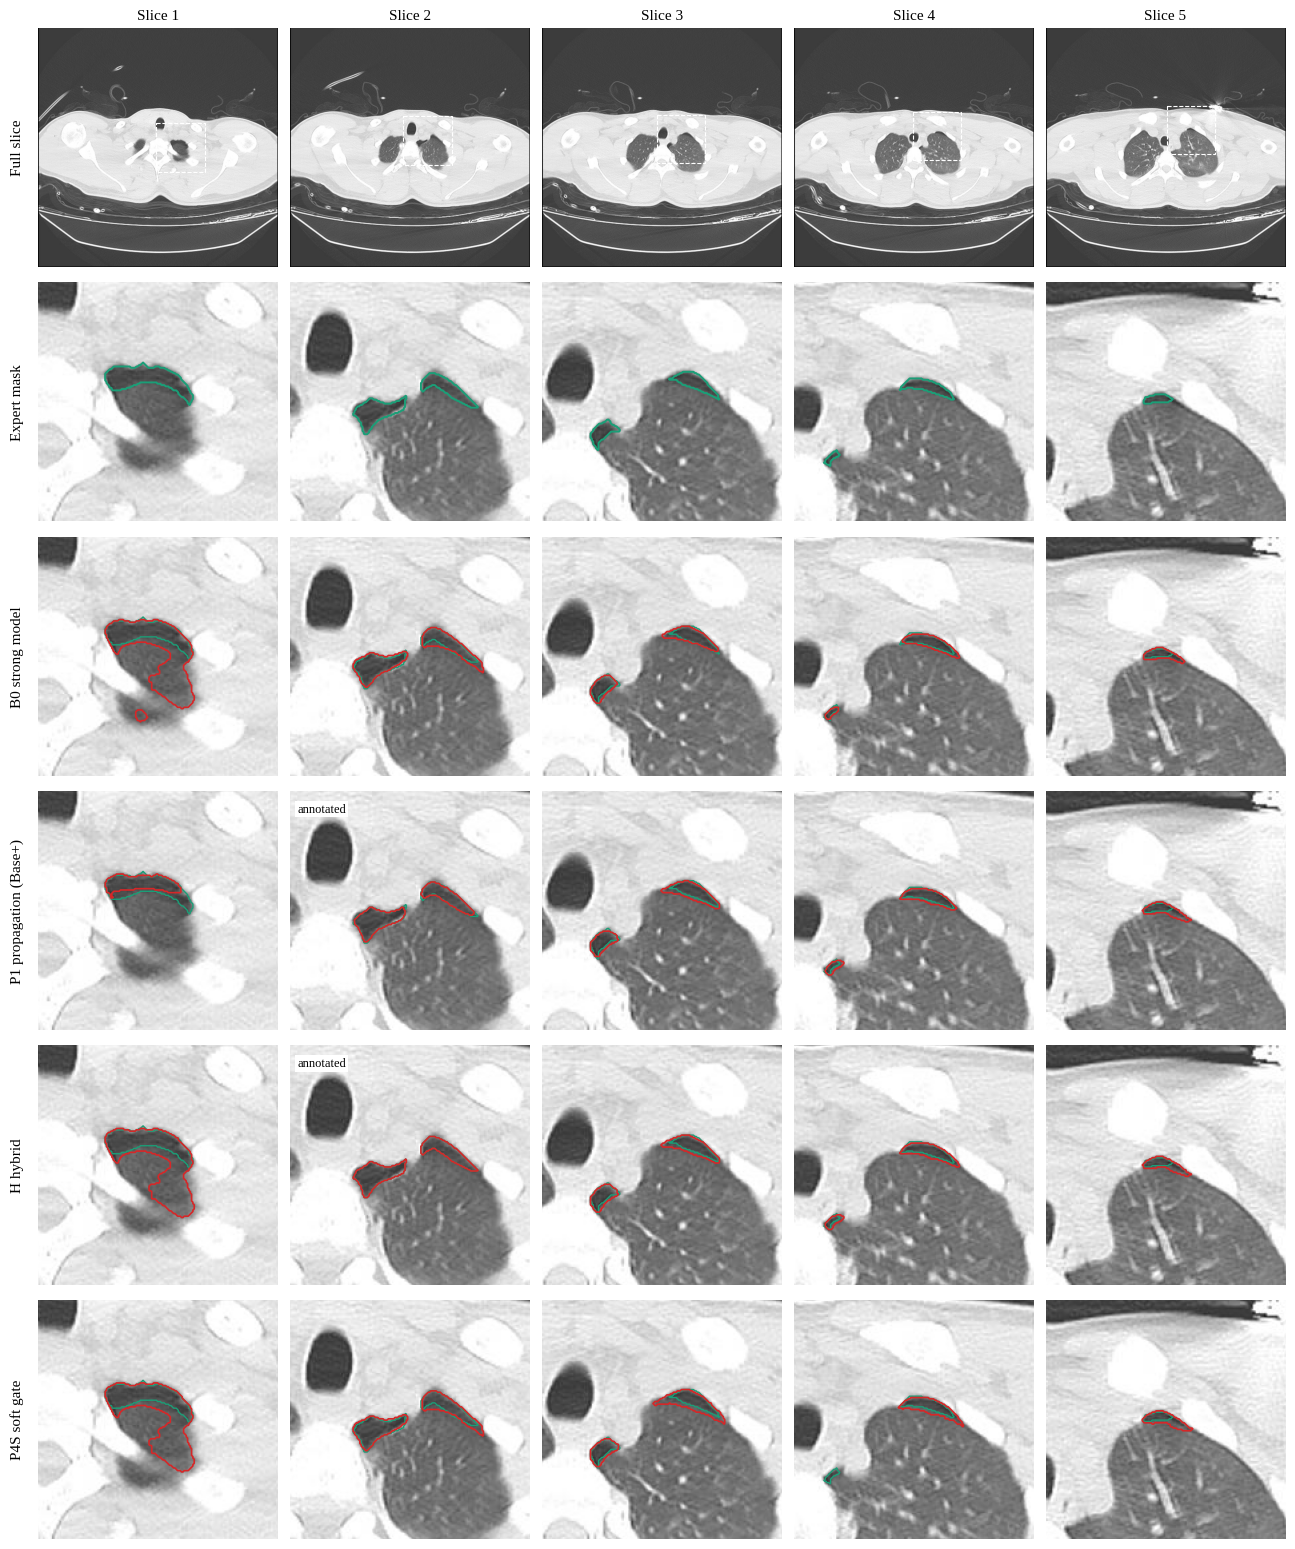

Anahtar kesit: 2 | Ciktilar: /content/drive/MyDrive/pnx_ek_analizler


In [10]:
YESIL, KIRMIZI = '#1B9E77', '#D62728'
pid = '1059440'   # ana not defterindeki kural: P1 pozitif kesit sayisi en fazla olan ilk test hastasi
assert pid in MASKE
sonuc, anahtarlar = MASKE[pid]
imgs, gts = VERI[pid]['imgs'], VERI[pid]['gts']
k = anahtarlar['en_buyuk']; n = len(imgs)
SATIR = [('Expert mask', None), ('B0 strong model', sonuc[('-', 'B0')]), ('P1 propagation (Base+)', sonuc[('en_buyuk', 'P1_B+')]),
         ('H hybrid', sonuc[('en_buyuk', 'H')]), ('P4S soft gate', sonuc[('-', 'P4S')])]


def kontur(ax, m, renk, lw=1.2):
    if m is not None and m.sum() > 0:
        ax.contour(m.astype(float), levels=[0.5], colors=[renk], linewidths=lw)


KIRP = []
for i in range(n):
    yig = np.stack([gts[i]] + [ms[i] for _, ms in SATIR[1:] if ms[i] is not None])
    ys, xs = np.where(yig.any(0))
    if len(ys) == 0:
        h, w = gts[i].shape; KIRP.append((w // 2, h // 2, 120)); continue
    KIRP.append((int(xs.mean()), int(ys.mean()), max(90, int(max(np.ptp(ys), np.ptp(xs)) * 0.75))))
fig, ax = plt.subplots(len(SATIR) + 1, n, figsize=(2.6 * n, 2.6 * (len(SATIR) + 1)))
for c in range(n):
    cx, cy, r = KIRP[c]
    ax[0, c].imshow(imgs[c]); ax[0, c].axis('off')
    ax[0, c].add_patch(plt.Rectangle((cx - r, cy - r), 2 * r, 2 * r, fill=False, ec='white', lw=0.8, ls='--'))
    ax[0, c].set_title(f'Slice {c + 1}', fontsize=11)
    for s, (et, ms) in enumerate(SATIR, 1):
        a = ax[s, c]
        a.imshow(imgs[c]); a.axis('off')
        a.set_xlim(max(cx - r, 0), min(cx + r, imgs[c].shape[1])); a.set_ylim(min(cy + r, imgs[c].shape[0]), max(cy - r, 0))
        kontur(a, gts[c], YESIL, 1.0 if ms is not None else 1.4)
        if ms is not None:
            kontur(a, ms[c], KIRMIZI)
            if c == k and et.startswith(('P1', 'H')):
                a.text(0.03, 0.95, 'annotated', transform=a.transAxes, fontsize=9, va='top',
                       bbox=dict(fc='white', ec='none', pad=1.5))
for s, (et, _) in enumerate([('Full slice', None)] + SATIR):
    ax[s, 0].text(-0.06, 0.5, et, transform=ax[s, 0].transAxes, rotation=90, ha='right', va='center', fontsize=11)
plt.tight_layout()
for uz_ in ('png', 'pdf'):
    plt.savefig(f'{OUT_DIR}/Figure3_example_patient.{uz_}', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Anahtar kesit:', k + 1, '| Ciktilar:', OUT_DIR)